In [1]:
import time
import pandas as pd

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Path to dataset files: /home/spandan/.cache/kagglehub/datasets/iammustafatz/diabetes-prediction-dataset/versions/1


In [4]:
data = pd.read_csv('datasets/diabetes_prediction_dataset.csv')

In [5]:
data.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


In [7]:
data.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [8]:
data['diabetes'].sum()

np.int64(8500)

In [9]:
x = data.drop('diabetes' , axis = 1)
y = data['diabetes']

In [10]:
x.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
0,Female,80.0,0,1,never,25.19,6.6,140
1,Female,54.0,0,0,No Info,27.32,6.6,80
2,Male,28.0,0,0,never,27.32,5.7,158
3,Female,36.0,0,0,current,23.45,5.0,155
4,Male,76.0,1,1,current,20.14,4.8,155


In [11]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

numerical_features = ['age' , 'hypertension' , 'heart_disease' , 'bmi' , 'HbA1c_level' , 'blood_glucose_level']
categorical_features = ['gender','smoking_history']

In [20]:
from sklearn.pipeline import Pipeline
numerical_transformer = Pipeline(
    steps=[
        ('scaler' , StandardScaler())
    ]
)
categorical_transformer = Pipeline(
    steps=[
        ('encoder' , OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(transformers=[
    ('num',numerical_transformer,numerical_features),
    ('cat',categorical_transformer,categorical_features)
])

In [21]:
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size = 0.2 , random_state=42)

In [22]:
x.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000


In [23]:
x_train_preprocessed = preprocessor.fit_transform(x_train)
x_test_preprocessed = preprocessor.transform(x_test)

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

beforeLR = LogisticRegression(max_iter=1000)

# Results for Simple LR (NO PCA OR LDA)

In [31]:
import time
startTrain = time.time()
beforeLR.fit(x_train_preprocessed,y_train)
endTrain=time.time()
simpleLRtime = endTrain - startTrain
print("time taken for training (simple LR) : ",simpleLRtime)

startPred = time.time()
y_pred_simple=beforeLR.predict(x_test_preprocessed)
endPred=time.time()
simpleLRpred = endPred - startPred
print("time taken for predicting (simple LR) : ",simpleLRpred)

time taken for training (simple LR) :  0.10990309715270996
time taken for predicting (simple LR) :  0.0009360313415527344


In [28]:
print(classification_report(y_test , y_pred_simple))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     18292
           1       0.86      0.62      0.72      1708

    accuracy                           0.96     20000
   macro avg       0.91      0.80      0.85     20000
weighted avg       0.96      0.96      0.96     20000



In [49]:
from sklearn.decomposition import PCA
pca = PCA(n_components=5)

x_train_pca = pca.fit_transform(x_train_preprocessed)
x_test_pca = pca.transform(x_test_preprocessed)
pcaLR = LogisticRegression(max_iter=1000)

# results for PCA

In [50]:
startTrain = time.time()
pcaLR.fit(x_train_pca,y_train)
endTrain=time.time()
pcaLRtime = endTrain - startTrain
print("time taken for training (pca LR) : ",pcaLRtime)

startPred = time.time()
y_pred_pca=pcaLR.predict(x_test_pca)
endPred=time.time()
pcaLRpred = endPred - startPred
print("time taken for predicting (pca LR) : ",pcaLRpred)

time taken for training (pca LR) :  0.08621954917907715
time taken for predicting (pca LR) :  0.000736236572265625


In [51]:
print(classification_report(y_test , y_pred_pca))

              precision    recall  f1-score   support

           0       0.96      0.99      0.98     18292
           1       0.87      0.61      0.71      1708

    accuracy                           0.96     20000
   macro avg       0.92      0.80      0.85     20000
weighted avg       0.96      0.96      0.96     20000



In [52]:
x_train_pca.shape

(80000, 5)

In [53]:
pca.explained_variance_ratio_

array([0.24124394, 0.14677958, 0.13222938, 0.11803732, 0.11560654])

In [54]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=1)
x_train_lda  = lda.fit_transform(
    x_train_preprocessed , y_train
)
x_test_lda = lda.transform(x_test_preprocessed)

ldaLR = LogisticRegression(max_iter=1000)

In [55]:
startTrain = time.time()
ldaLR.fit(x_train_lda,y_train)
endTrain=time.time()
ldaLRtime = endTrain - startTrain
print("time taken for training (lda LR) : ",ldaLRtime)

startPred = time.time()
y_pred_lda=ldaLR.predict(x_test_lda)
endPred=time.time()
ldaLRpred = endPred - startPred
print("time taken for predicting (lda LR) : ",ldaLRpred)

time taken for training (lda LR) :  0.07667183876037598
time taken for predicting (lda LR) :  0.0009381771087646484


In [56]:
print(classification_report(y_test , y_pred_lda))

              precision    recall  f1-score   support

           0       0.96      0.99      0.98     18292
           1       0.86      0.58      0.70      1708

    accuracy                           0.96     20000
   macro avg       0.91      0.79      0.84     20000
weighted avg       0.95      0.96      0.95     20000



In [57]:
analysis = {
    'simple' : simpleLRpred ,
    'PCA' : pcaLRpred,
    'LDA' : ldaLRpred
}
analysis

{'simple': 0.0009360313415527344,
 'PCA': 0.000736236572265625,
 'LDA': 0.0009381771087646484}

In [71]:
anal = pd.DataFrame(analysis)

In [62]:
analysis = {
    'type': ['Simple LR', 'PCA LR', 'LDA LR'],
    'training time': [simpleLRtime, pcaLRtime, ldaLRtime]
}

In [63]:
analysis

{'type': ['Simple LR', 'PCA LR', 'LDA LR'],
 'training time': [0.10990309715270996,
  0.08621954917907715,
  0.07667183876037598]}

In [64]:
anal = pd.DataFrame(analysis)
anal.head()

,type,training time
0,Simple LR,0.109903
1,PCA LR,0.086220
2,LDA LR,0.076672


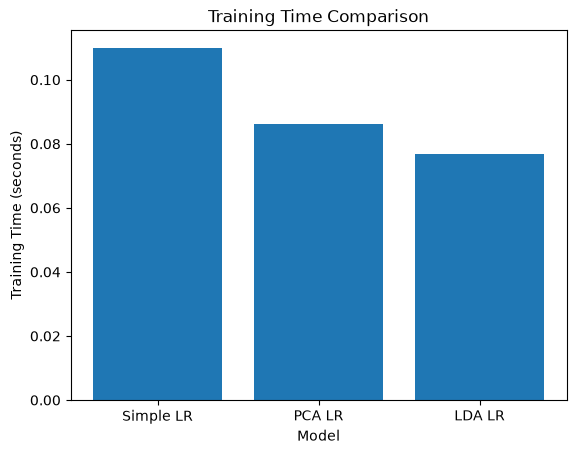

In [70]:
import matplotlib.pyplot as plt
plt.bar(anal['type'], anal['training time'])
plt.xlabel('Model')
plt.ylabel('Training Time (seconds)')
plt.title('Training Time Comparison')
plt.show()